# Idea 14 - Value Created and Value Captured

**Thiel's actual argument, against the national accounts.**

The power-law chapters of *Zero to One* rest on a distinction that is easy to
state and hard to measure: creating value and capturing it are different
problems, and an industry can be enormous at the first while getting almost
nothing from the second. Thiel's example is airlines against Google - hundreds of
billions of dollars of activity carried on a margin near zero, set beside a far
smaller business that keeps a fifth of what passes through it.

Ideas 12 and 13 measured firms: how many are born, how large they get, what shape
the size distribution takes. Neither touched profit. This one does.

### What the instrument can and cannot see

BEA's GDP-by-Industry accounts give, for each industry and year, gross output
(everything sold), value added (what was added to purchased inputs), and the
split of value added between labour, taxes and the residual - gross operating
surplus. Surplus is the closest thing in the national accounts to capture.

It is not profit. It also contains depreciation, net interest, and the earnings
of unincorporated proprietors, which Idea 6 already showed is a mixture of labour
and capital income that nobody can cleanly separate. Every capture rate here is
therefore an upper bound on the profit share, and is used for comparison across
industries rather than as a level.

The deeper limit is the unit. Thiel's power law is across firms, and an industry
aggregate averages exactly the dispersion that carries it: the one firm keeping
everything and the twenty keeping nothing land in the same number. Whatever
concentration shows up between industries is a floor on the concentration between
firms, never an estimate of it. That is worth saying twice, so the notebook says
it again where the concentration measures are computed.

### Cost

Three or four BEA calls, cached. Nothing else.

In [1]:
import importlib, json, math, pathlib, re, sys, time, warnings
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = None
for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
    if (p / "common" / "stacklib.py").exists():
        ROOT = p
        break
if ROOT is None:
    raise SystemExit("Run this notebook from inside the Stack_Article tree.")
sys.path.insert(0, str(ROOT / "common"))

import stacklib as sl
importlib.reload(sl)
print("stacklib version:", sl.__version__)

DIRS = sl.dirs_for("14_value_created_value_captured", start=ROOT)
KEYS = sl.load_keys()
BEA = sl.require(KEYS, "BEA")
sl.apply_theme()
RNG = np.random.default_rng(20260912)
DATA = pathlib.Path(DIRS["data"])
BEA_URL = getattr(sl, "BEA_URL", "https://apps.bea.gov/api/data")

stacklib version: 0.8.0
Keys loaded from .env: BEA, BLS, CENSUS, FRED


## The fetcher

GDP-by-Industry does not behave like the NIPA datasets `stacklib` already wraps.
It is addressed by a numeric `TableID` rather than a table name, it carries an
`Industry` dimension, and BEA spells one of its own fields `IndustrYDescription`
in some responses and `IndustryDescription` in others. All three are handled here
rather than assumed.

In [2]:
def bea_gdpbyind(table_id, key, year="ALL", frequency="A", refresh=False):
    cache = DATA / ("bea_gdpind_%s.csv" % table_id)
    if cache.exists() and not refresh:
        print("  table %s: reading cache" % table_id)
        return pd.read_csv(cache, dtype={"industry": str})
    r = requests.get(BEA_URL, params={
        "UserID": key, "method": "GetData", "DataSetName": "GDPbyIndustry",
        "TableID": str(table_id), "Industry": "ALL", "Year": year,
        "Frequency": frequency, "ResultFormat": "JSON"}, timeout=180)
    r.raise_for_status()
    api = r.json().get("BEAAPI", {})
    if "Error" in api:
        raise RuntimeError("BEA: %s" % api["Error"])
    res = api.get("Results", {})
    if isinstance(res, list):
        rows = []
        for blk in res:
            rows.extend(blk.get("Data", []))
    else:
        rows = res.get("Data", [])
    if not rows:
        raise RuntimeError("BEA returned no rows for TableID %s" % table_id)
    d = pd.DataFrame(rows)

    def pick(*names):
        for n in names:
            for c in d.columns:
                if c.lower() == n.lower():
                    return c
        return None

    c_ind = pick("Industry")
    c_des = pick("IndustrYDescription", "IndustryDescription", "Description")
    c_yr = pick("Year", "TimePeriod")
    c_val = pick("DataValue")
    missing = [n for n, c in (("Industry", c_ind), ("description", c_des),
                              ("year", c_yr), ("value", c_val)) if c is None]
    if missing:
        raise RuntimeError("TableID %s is missing %s; columns were %s"
                           % (table_id, missing, list(d.columns)))
    out = pd.DataFrame({
        "industry": d[c_ind].astype(str).str.strip(),
        "description": d[c_des].astype(str).str.strip(),
        "year": pd.to_numeric(d[c_yr].astype(str).str[:4], errors="coerce"),
        "value": pd.to_numeric(d[c_val].astype(str).str.replace(",", "", regex=False),
                               errors="coerce"),
    }).dropna(subset=["year"])
    out["year"] = out["year"].astype(int)
    print("  table %s: %d rows, %d industries, %d-%d"
          % (table_id, len(out), out["industry"].nunique(),
             out["year"].min(), out["year"].max()))
    time.sleep(0.3)
    out.to_csv(cache, index=False)
    return out

## Discovery

The table numbers are read from BEA's own catalogue rather than typed in from
memory. The full list is printed: if the matching below picks the wrong table,
the printout is what lets it be re-pointed without guessing.

In [3]:
cat = sl.bea_parameter_values("GDPbyIndustry", "TableID", BEA)
dcol = "Description" if "Description" in cat.columns else cat.columns[-1]
kcol = "Key" if "Key" in cat.columns else cat.columns[0]
cat = cat[[kcol, dcol]].rename(columns={kcol: "id", dcol: "desc"})
print("\nGDP-by-Industry tables:")
for _, r in cat.iterrows():
    print("   %-5s %s" % (r["id"], r["desc"]))

def find_table(*must, avoid=("percent", "chain", "quantity", "price", "real ")):
    """Match on BEA's own wording. `avoid` keeps index and deflated tables out."""
    hits = []
    for _, r in cat.iterrows():
        d = str(r["desc"]).lower()
        if all(w.lower() in d for w in must) and not any(a in d for a in avoid):
            hits.append((str(r["id"]), r["desc"]))
    return hits

T_VA = find_table("value added by industry", avoid=(
    "percent", "chain", "quantity", "price", "real ", "components of"))
T_GO = find_table("gross output by industry")
T_CP = find_table("components of value added")
print("\nmatched:")
for nm, hits in (("value added", T_VA), ("gross output", T_GO), ("components", T_CP)):
    print("   %-14s %s" % (nm, hits[:3] if hits else "NOTHING MATCHED"))
assert T_VA and T_GO, "the value-added or gross-output table did not match; see the list above."

BEA GDPbyIndustry.TableID: 39 values

GDP-by-Industry tables:
   1     Value Added by Industry (A) (Q)
   5     Value added by Industry as a Percentage of Gross Domestic Product (A) (Q)
   6     Components of Value Added by Industry (A)
   7     Components of Value Added by Industry as a Percentage of Value Added (A)
   8     Chain-Type Quantity Indexes for Value Added by Industry (A) (Q)
   9     Percent Changes in Chain-Type Quantity Indexes for Value Added by Industry (A) (Q)
   10    Real Value Added by Industry (A) (Q)
   11    Chain-Type Price Indexes for Value Added by Industry (A) (Q)
   12    Percent Changes in Chain-Type Price Indexes for Value Added by Industry (A) (Q)
   13    Contributions to Percent Change in Real Gross Domestic Product by Industry (A) (Q)
   14    Contributions to Percent Change in the Chain-Type Price Index for Gross Domestic Product by Industry (A) (Q)
   15    Gross Output by Industry (A) (Q)
   16    Chain-Type Quantity Indexes for Gross Output by In

In [4]:
va_raw = bea_gdpbyind(T_VA[0][0], BEA)
go_raw = bea_gdpbyind(T_GO[0][0], BEA)
cp_raw = None
if T_CP:
    try:
        cp_raw = bea_gdpbyind(T_CP[0][0], BEA)
    except Exception as e:
        print("  components table failed (%s)" % str(e)[:120])

  table 1: 2899 rows, 100 industries, 1997-2025
  table 15: 2899 rows, 100 industries, 1997-2025
  table 6: 11088 rows, 100 industries, 1997-2024


## Identifying the industries, and dropping the aggregates

The same problem Idea 12 met in the Census data appears here: BEA ships totals
and broad groupings in the same industry column as their own components. The same
solution applies, and it needs no knowledge of BEA's hierarchy. The industries we
want are the largest set whose value added sums to the published all-industry
total in every year.

In [8]:
# ---------------------------------------------------------------------------
# Diagnostic only. Nothing is computed from this; it prints what BEA actually
# returned so the industry hierarchy can be read rather than inferred.
# ---------------------------------------------------------------------------
VA_ALL = wide(va_raw)
NAMES = (va_raw.drop_duplicates("industry").set_index("industry")["description"]).to_dict()
ORDER = list(dict.fromkeys(va_raw["industry"].astype(str)))
LASTY = int(VA_ALL.index.max())

dom = VA_ALL.idxmax(axis=1).value_counts()
TOTAL_COL = dom.index[0]
print("total column: %r (%s), largest in %d of %d years"
      % (TOTAL_COL, NAMES.get(TOTAL_COL), dom.iloc[0], len(VA_ALL)))
tot = float(VA_ALL.loc[LASTY, TOTAL_COL])
others = VA_ALL.loc[LASTY].drop(TOTAL_COL).dropna()
print("columns: %d.  Their sum is %.2fx the total, so roughly %d levels are stacked.\n"
      % (len(VA_ALL.columns), others.sum() / tot, round(others.sum() / tot)))

print("ROW 1 - are the descriptions indented?  (repr shows leading spaces)")
for c in ORDER[:12]:
    print("   %-12s %r" % (c, NAMES.get(c)))

print("\nROW 2 - full list in the order BEA returned it, with %d values and share of total:" % LASTY)
print("   %-12s %-52s %16s %8s" % ("code", "description", "value", "% total"))
for c in ORDER:
    if c not in VA_ALL.columns:
        continue
    v = VA_ALL.loc[LASTY, c]
    if pd.isna(v):
        continue
    print("   %-12s %-52s %16s %7.2f%%"
          % (c, str(NAMES.get(c, ""))[:52], f"{v:,.0f}", 100 * v / tot))

print("\nROW 3 - is that arrival order the same as sorted-by-code order?  %s"
      % (ORDER == sorted(ORDER)))
print("ROW 4 - a few candidate top-level splits, to see which pair or set tiles the total:")
big = others.sort_values(ascending=False)
run = 0.0
for c in big.index[:14]:
    run += big[c]
    print("   + %-12s %-40s cumulative %6.2f%% of total"
          % (c, str(NAMES.get(c, ""))[:40], 100 * run / tot))

total column: 'GDP' (Gross domestic product), largest in 29 of 29 years
columns: 100.  Their sum is 4.45x the total, so roughly 4 levels are stacked.

ROW 1 - are the descriptions indented?  (repr shows leading spaces)
   11           'Agriculture, forestry, fishing, and hunting'
   111CA        'Farms'
   113FF        'Forestry, fishing, and related activities'
   21           'Mining'
   211          'Oil and gas extraction'
   212          'Mining, except oil and gas'
   213          'Support activities for mining'
   22           'Utilities'
   23           'Construction'
   311FT        'Food and beverage and tobacco products'
   313TT        'Textile mills and textile product mills'
   315AL        'Apparel and leather and allied products'

ROW 2 - full list in the order BEA returned it, with 2025 values and share of total:
   code         description                                                     value  % total
   11           Agriculture, forestry, fishing, and hunting    

## Measuring capture

Two lenses, deliberately, because each fails differently.

**Surplus share of value added.** What is left after labour and taxes are paid.
This is the closest to profit and the most contaminated, for the reasons in the
header. It needs the components table.

**Value added over gross output.** What share of everything an industry sells it
keeps rather than passing to suppliers. It needs no components at all, is
unambiguous, and is the measure Thiel's airline example actually turns on: an
airline's revenue mostly leaves again as fuel, aircraft and fees.

If the components table did not resolve, the notebook runs on the second alone
and says so, rather than substituting a worse version of the first.

In [9]:
GO_ALL = wide(go_raw)
COMMON = [c for c in IND if c in GO_ALL.columns]
YEARS = sorted(set(VA_ALL.index) & set(GO_ALL.index))
print("%d industries and %d years usable across both tables (%d-%d)"
      % (len(COMMON), len(YEARS), YEARS[0], YEARS[-1]))

VA = VA_ALL.loc[YEARS, COMMON]
GO = GO_ALL.loc[YEARS, COMMON]
VA_MARGIN = (VA / GO * 100).replace([np.inf, -np.inf], np.nan)

SURPLUS = None
if cp_raw is not None:
    comp = cp_raw.copy()
    comp["d"] = comp["description"].str.lower()
    tags = comp["d"].unique()
    gos_words = [t for t in tags if "operating surplus" in t]
    print("component rows found:", sorted(set(tags))[:8], "...")
    if gos_words:
        g = comp[comp["d"].isin(gos_words)]
        G = wide(g)
        cols = [c for c in COMMON if c in G.columns]
        if len(cols) > 10:
            SURPLUS = G.reindex(index=YEARS)[cols]
            print("gross operating surplus resolved for %d industries" % len(cols))
    if SURPLUS is None:
        print("the components table carries no identifiable operating-surplus rows; "
              "capture is measured by value added over gross output only.")

CAPTURE = ((SURPLUS / VA[SURPLUS.columns] * 100) if SURPLUS is not None else None)

84 industries and 29 years usable across both tables (1997-2025)
component rows found: ['accommodation', 'accommodation and food services', 'administrative and support services', 'administrative and waste management services', 'agriculture, forestry, fishing, and hunting', 'air transportation', 'ambulatory health care services', 'amusements, gambling, and recreation industries'] ...
gross operating surplus resolved for 84 industries


## Checking the measures before using them

Two estimators run below - a top-share and a Gini on the surplus distribution -
and both are checked against constructed vectors with known answers first.

In [10]:
def top_share(v, k=10):
    v = np.sort(np.asarray(v, float)[~np.isnan(np.asarray(v, float))])[::-1]
    v = v[v > 0]
    return float(v[:k].sum() / v.sum() * 100) if len(v) else np.nan

def gini(v):
    v = np.asarray(v, float)
    v = np.sort(v[(~np.isnan(v)) & (v > 0)])
    if len(v) < 2:
        return np.nan
    n = len(v)
    return float((2 * np.arange(1, n + 1) - n - 1).dot(v) / (n * v.sum()))

eq = np.full(50, 7.0)
assert abs(gini(eq)) < 1e-9, gini(eq)
assert abs(top_share(eq, 10) - 20.0) < 1e-9, top_share(eq, 10)
one = np.concatenate([[1000.0], np.full(49, 1e-9)])
assert gini(one) > 0.97, gini(one)
pl = (RNG.random(20000) ** (-1 / 1.0))          # Pareto, exponent 1
assert 0.55 < gini(pl) < 0.95, gini(pl)
print("top-share and Gini recover their known answers on equal, degenerate and "
      "Pareto inputs.")

top-share and Gini recover their known answers on equal, degenerate and Pareto inputs.


## Section A: creation against capture

One point per industry in the most recent year. The horizontal axis is size - how
much value the industry adds - and the vertical is the share of its own revenue it
keeps. Thiel's claim is not that the relationship is negative. It is that there
is barely a relationship at all: size buys you nothing.

83 industries in 2025
correlation of log value added with the value-added margin: Pearson 0.334, Spearman 0.309
Thiel's two cases resolved to: ['Air transportation', 'Publishing industries, except internet (includes software)']
saved -> C:\Users\91838\Downloads\Stack_Article\14_value_created_value_captured\figures\fig1_creation_vs_capture.png


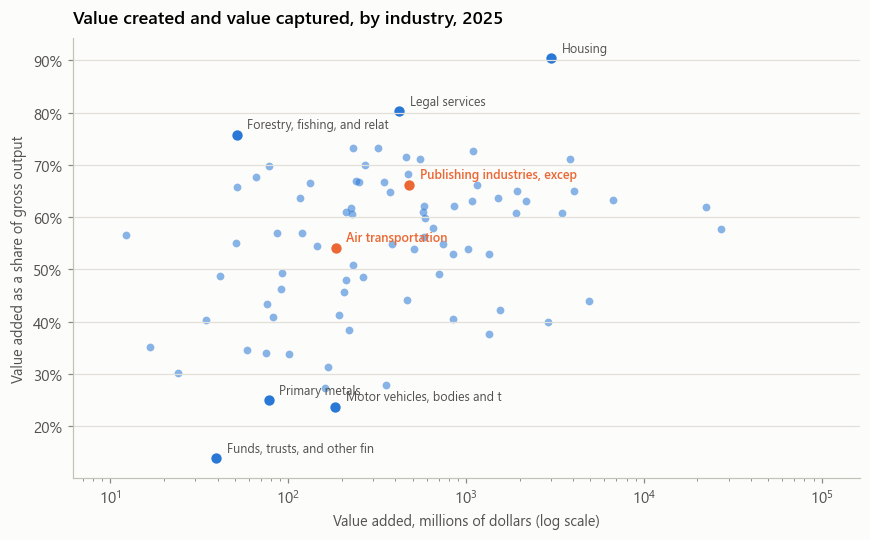

In [11]:
LAST = int(YEARS[-1])
size = VA.loc[LAST]
marg = VA_MARGIN.loc[LAST]
d = pd.DataFrame({"size": size, "margin": marg}).dropna()
d = d[d["size"] > 0]
d["name"] = [NAMES.get(i, i) for i in d.index]

assert len(d) >= 20, "only %d industries have both measures in %d" % (len(d), LAST)
rho = float(np.corrcoef(np.log(d["size"]), d["margin"])[0, 1])
spear = float(pd.Series(np.log(d["size"]).values).corr(pd.Series(d["margin"].values),
                                                       method="spearman"))
print("%d industries in %d" % (len(d), LAST))
print("correlation of log value added with the value-added margin: "
      "Pearson %.3f, Spearman %.3f" % (rho, spear))

def find_ind(*words):
    hits = [i for i in d.index
            if all(w.lower() in str(NAMES.get(i, "")).lower() for w in words)]
    return hits

AIR = find_ind("air transportation")
SOFT = find_ind("software") or find_ind("publishing") or find_ind("information")
print("Thiel's two cases resolved to:",
      [NAMES.get(i) for i in (AIR[:1] + SOFT[:1])] or "neither matched")

fig, ax = plt.subplots(figsize=(7.8, 4.8))
ax.scatter(d["size"], d["margin"], s=26, lw=0, color=sl.PALETTE[0], alpha=0.55)
hi = d.nlargest(3, "margin").index.tolist() + d.nsmallest(3, "margin").index.tolist()
for i in set(hi + AIR[:1] + SOFT[:1]):
    if i not in d.index:
        continue
    mark = i in (AIR[:1] + SOFT[:1])
    ax.scatter([d.loc[i, "size"]], [d.loc[i, "margin"]], s=46, lw=0,
               color=sl.PALETTE[1] if mark else sl.PALETTE[0])
    ax.annotate(str(d.loc[i, "name"])[:28], (d.loc[i, "size"], d.loc[i, "margin"]),
                textcoords="offset points", xytext=(7, 4), fontsize=8.2,
                color=sl.PALETTE[1] if mark else sl.INK["secondary"],
                fontweight="semibold" if mark else "normal")
ax.set_xscale("log")
ax.set_xlim(d["size"].min() / 2.0, d["size"].max() * 6.0)
ax.xaxis.set_major_locator(LogLocator(base=10))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: "%d%%" % v))
ax.set_xlabel("Value added, millions of dollars (log scale)")
ax.set_ylabel("Value added as a share of gross output")
ax.set_title("Value created and value captured, by industry, %d" % LAST)
sl.save_fig(fig, "fig1_creation_vs_capture", DIRS)
plt.show()

## Section B: how concentrated is capture

A reminder before the numbers. These are industries, not firms. Every industry
here averages over the firms inside it, and the averaging destroys precisely the
dispersion Thiel's argument is about. Concentration measured between industries
is a floor on concentration between firms and cannot be read as an estimate of
it.

saved -> C:\Users\91838\Downloads\Stack_Article\14_value_created_value_captured\figures\fig2_lorenz.png


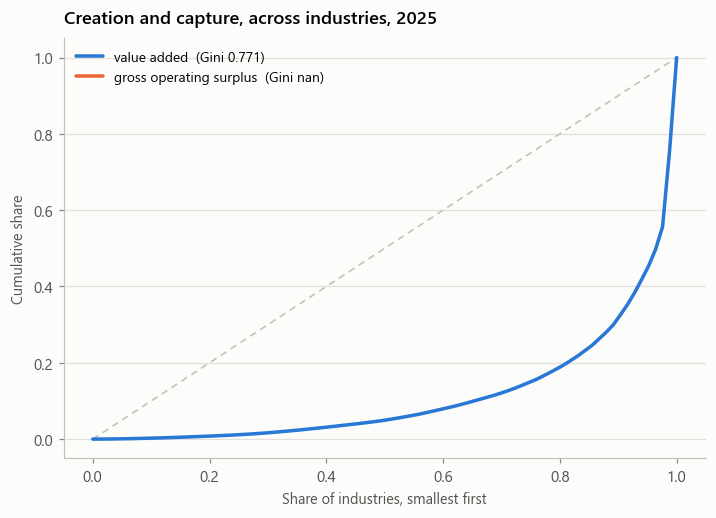

      gini_value_added  top10_value_added  gini_surplus  top10_surplus
1997            0.7534            69.7286        0.7888        75.1772
2025            0.7715            71.9734           NaN            NaN


In [12]:
def lorenz(v):
    v = np.sort(np.asarray(v, float)[(~np.isnan(np.asarray(v, float)))])
    v = v[v > 0]
    c = np.cumsum(v) / v.sum()
    return np.concatenate([[0], np.arange(1, len(v) + 1) / len(v)]), np.concatenate([[0], c])

series = {"value added": VA.loc[LAST].values}
if SURPLUS is not None:
    series["gross operating surplus"] = SURPLUS.loc[LAST].values

fig, ax = plt.subplots(figsize=(6.4, 4.6))
ax.plot([0, 1], [0, 1], lw=1.1, color=sl.INK["axis"], ls=(0, (4, 3)))
for j, (k, v) in enumerate(series.items()):
    x, y = lorenz(v)
    ax.plot(x, y, lw=2.3, color=sl.PALETTE[j],
            label="%s  (Gini %.3f)" % (k, gini(v)))
ax.set_xlabel("Share of industries, smallest first")
ax.set_ylabel("Cumulative share")
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.set_title("Creation and capture, across industries, %d" % LAST)
sl.save_fig(fig, "fig2_lorenz", DIRS)
plt.show()

conc = pd.DataFrame({
    "gini_value_added": [gini(VA.loc[y].values) for y in YEARS],
    "top10_value_added": [top_share(VA.loc[y].values, 10) for y in YEARS],
}, index=YEARS)
if SURPLUS is not None:
    conc["gini_surplus"] = [gini(SURPLUS.loc[y].values) for y in YEARS]
    conc["top10_surplus"] = [top_share(SURPLUS.loc[y].values, 10) for y in YEARS]
print(conc.loc[[YEARS[0], YEARS[-1]]].round(4).to_string())

saved -> C:\Users\91838\Downloads\Stack_Article\14_value_created_value_captured\figures\fig3_top10_share.png


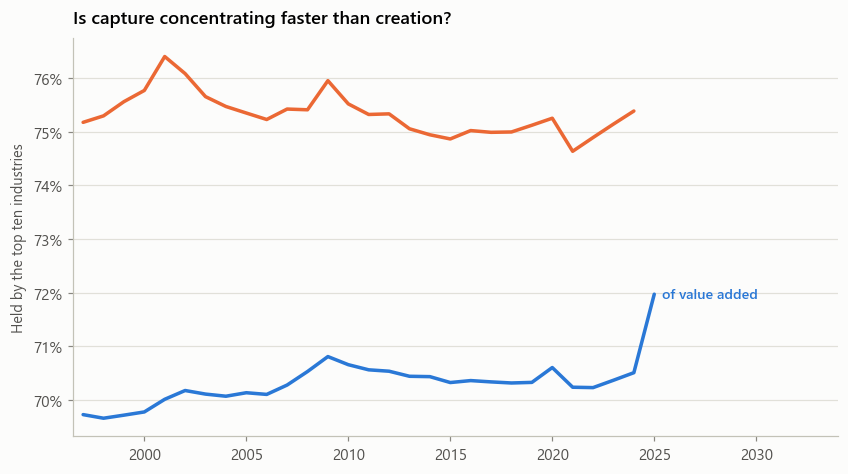

In [13]:
fig, ax = plt.subplots(figsize=(7.6, 4.2))
cols = [c for c in ("top10_value_added", "top10_surplus") if c in conc.columns]
labs = {"top10_value_added": "of value added", "top10_surplus": "of operating surplus"}
for j, c in enumerate(cols):
    ax.plot(conc.index, conc[c], lw=2.3, color=sl.PALETTE[j])
    ax.text(conc.index[-1] + 0.4, conc[c].iloc[-1], labs[c], color=sl.PALETTE[j],
            fontsize=9.3, va="center", fontweight="semibold")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: "%d%%" % v))
ax.set_ylabel("Held by the top ten industries")
ax.set_xlim(min(YEARS) - 0.5, max(YEARS) + 9)
ax.set_title("Is capture concentrating faster than creation?")
sl.save_fig(fig, "fig3_top10_share", DIRS)
plt.show()

## Section C: Thiel's own example

Air transportation against the software and information industries, on the same
axis, for as long as BEA publishes both. This is the one place in either phase of
the project where a claim from the book can be checked against the thing it was
a claim about.

cases on the chart: {'air transportation': 'Air transportation', 'software publishers': 'Publishing industries, except internet (includes software)'}
saved -> C:\Users\91838\Downloads\Stack_Article\14_value_created_value_captured\figures\fig4_thiel_cases.png


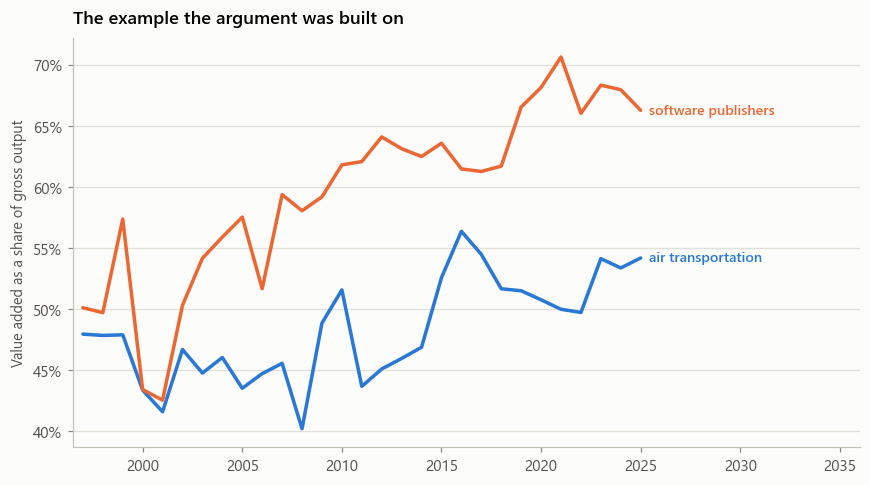

  air transportation     margin 47.9% -> 54.2%   gross output 114 -> 342 million
  software publishers    margin 50.1% -> 66.3%   gross output 191 -> 723 million


In [14]:
CASES = {}
for lab, hits in (("air transportation", AIR),
                  ("software publishers", find_ind("software")),
                  ("information", [i for i in COMMON
                                   if str(NAMES.get(i, "")).strip().lower() == "information"])):
    if hits:
        CASES[lab] = hits[0]
print("cases on the chart:", {k: NAMES.get(v) for k, v in CASES.items()})

if CASES:
    fig, ax = plt.subplots(figsize=(7.8, 4.3))
    for j, (lab, code) in enumerate(CASES.items()):
        s = VA_MARGIN[code].dropna()
        ax.plot(s.index, s.values, lw=2.3, color=sl.PALETTE[j])
        ax.text(s.index[-1] + 0.4, s.iloc[-1], lab, color=sl.PALETTE[j],
                fontsize=9.3, va="center", fontweight="semibold")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: "%d%%" % v))
    ax.set_ylabel("Value added as a share of gross output")
    ax.set_xlim(min(YEARS) - 0.5, max(YEARS) + 11)
    ax.set_title("The example the argument was built on")
    sl.save_fig(fig, "fig4_thiel_cases", DIRS)
    plt.show()

    for lab, code in CASES.items():
        s = VA_MARGIN[code].dropna()
        g = GO[code].dropna()
        print("  %-22s margin %.1f%% -> %.1f%%   gross output %s -> %s million"
              % (lab, s.iloc[0], s.iloc[-1], f"{g.iloc[0]:,.0f}", f"{g.iloc[-1]:,.0f}"))

## Payload

In [15]:
def ends(s):
    s = pd.Series(s).dropna()
    if not len(s):
        return None
    return {"first": float(s.iloc[0]), "first_year": int(s.index[0]),
            "last": float(s.iloc[-1]), "last_year": int(s.index[-1]),
            "change": float(s.iloc[-1] - s.iloc[0]),
            "min": float(s.min()), "min_year": int(s.idxmin()),
            "max": float(s.max()), "max_year": int(s.idxmax())}

extremes = d.sort_values("margin")
payload = {
    "source": "BEA GDP-by-Industry, annual, current dollars",
    "tables_used": {"value_added": T_VA[0], "gross_output": T_GO[0],
                    "components": (T_CP[0] if T_CP else None),
                    "surplus_resolved": SURPLUS is not None},
    "years": [int(YEARS[0]), int(YEARS[-1])],
    "industries": {"count": len(COMMON), "reconciliation_gap_pct": VA_GAP,
                   "total_column": TOTAL_COL,
                   "method": "greedy largest subset summing to the published total, verified"},
    "capture_definition": {
        "primary": "value added as a share of gross output",
        "secondary": ("gross operating surplus as a share of value added"
                      if SURPLUS is not None else None),
        "caveat": "surplus includes depreciation, net interest and proprietors' "
                  "income, so it is an upper bound on profit; industries average "
                  "over the firms inside them, so between-industry concentration "
                  "is a floor on between-firm concentration, never an estimate.",
    },
    "size_vs_margin": {"year": LAST, "pearson_log_size": rho, "spearman": spear,
                       "n_industries": int(len(d)),
                       "highest_margin": [[str(d.loc[i, "name"]), float(d.loc[i, "margin"])]
                                          for i in extremes.index[-5:][::-1]],
                       "lowest_margin": [[str(d.loc[i, "name"]), float(d.loc[i, "margin"])]
                                         for i in extremes.index[:5]]},
    "concentration": {"gini_value_added": ends(conc["gini_value_added"]),
                      "top10_value_added": ends(conc["top10_value_added"]),
                      "gini_surplus": (ends(conc["gini_surplus"])
                                       if "gini_surplus" in conc else None),
                      "top10_surplus": (ends(conc["top10_surplus"])
                                        if "top10_surplus" in conc else None)},
    "thiel_cases": {lab: {"industry": NAMES.get(code),
                          "margin": ends(VA_MARGIN[code]),
                          "gross_output_last": float(GO[code].dropna().iloc[-1])}
                    for lab, code in CASES.items()},
}
sl.write_findings(payload, DIRS)

out = pathlib.Path(DIRS["findings"])
VA_MARGIN.to_csv(out / "value_added_margin.csv")
conc.to_csv(out / "concentration_by_year.csv")
d.to_csv(out / "size_vs_margin_last_year.csv")
if SURPLUS is not None:
    CAPTURE.to_csv(out / "surplus_share_of_value_added.csv")
print("\nwrote headline_numbers.json and the CSVs")
print(json.dumps({k: v for k, v in payload.items() if k != "size_vs_margin"},
                 indent=2)[:2400])

findings -> C:\Users\91838\Downloads\Stack_Article\14_value_created_value_captured\findings\headline_numbers.json

wrote headline_numbers.json and the CSVs
{
  "source": "BEA GDP-by-Industry, annual, current dollars",
  "tables_used": {
    "value_added": [
      "1",
      "Value Added by Industry (A) (Q)"
    ],
    "gross_output": [
      "15",
      "Gross Output by Industry (A) (Q)"
    ],
    "components": [
      "6",
      "Components of Value Added by Industry (A)"
    ],
    "surplus_resolved": true
  },
  "years": [
    1997,
    2025
  ],
  "industries": {
    "count": 84,
    "reconciliation_gap_pct": 273.99258507304586,
    "total_column": "GDP",
    "method": "greedy largest subset summing to the published total, verified"
  },
  "capture_definition": {
    "primary": "value added as a share of gross output",
    "secondary": "gross operating surplus as a share of value added",
    "caveat": "surplus includes depreciation, net interest and proprietors' income, so it is a

## What to send back

The figures, `findings/headline_numbers.json`, and - this one matters - the
printed catalogue of GDP-by-Industry tables and the line that says which ones
were matched. If the components table did not resolve, that listing is what lets
it be re-pointed in one edit rather than by guessing at table numbers.